# Intensity self-imaging without mode recurrence: benchmarks, grating scan and sensitivity
**H. Hamam**

This notebook reproduces every number and figure of the study in one pass. All lengths are in units of the wavelength. It covers

1. the three-order closed-form benchmark and its recurrence figure,
2. two nine-mode two-dimensional benchmarks with a click and no-click detector model, one of them with an exact maximum overlap of 1/4,
3. a conducting screen with three propagating orders, where each polarization recurs between planes placed symmetrically about a symmetry plane,
4. an exhaustive scan of one-, two- and three-slit mirror-symmetric screens at a period of 2.53 wavelengths, giving the best unpolarized profile discrepancy as a function of the allowed mode overlap,
5. the screen selected from that scan, and
6. the sensitivity of the ideal modes and of the selected screen to wavelength, plane position, slit geometry and polarization.

The screens are zero-thickness perfect conductors, invariant along the slits, at normal incidence. The detector models are prescribed. No measured data enter.

In [1]:
from pathlib import Path
from itertools import product
import json, time
import numpy as np
from scipy.special import jv
from scipy.optimize import minimize_scalar, differential_evolution, minimize
import matplotlib as mpl
import matplotlib.pyplot as plt

K = 2*np.pi                                   # wavenumber; all lengths are in wavelengths
try:
    from google.colab import drive
except ImportError:
    work_dir = Path('outputs/Quantum_Field_Diffraction'); backup_dir = None
else:
    drive.mount('/content/drive')
    work_dir = Path('/content/Quantum_Field_Diffraction')
    backup_dir = Path('/content/drive/MyDrive/Outputs/Quantum_Field_Diffraction')
    backup_dir.mkdir(parents=True, exist_ok=True)
work_dir.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({'font.size': 9, 'axes.labelsize': 9, 'axes.titlesize': 9, 'legend.fontsize': 8,
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.linewidth': .7, 'lines.linewidth': 1.6, 'legend.frameon': False, 'savefig.dpi': 300,
                     'figure.dpi': 110, 'mathtext.fontset': 'dejavusans'})
BLUE, ORANGE, GREEN, PURPLE, GREY = '#0072B2', '#D55E00', '#009E73', '#7B3FA0', '#555555'
summary = {}

def save_figure(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(work_dir/f'{name}.{ext}', bbox_inches='tight')
    print(f'Figure written: {work_dir/name}.pdf')
print('Working directory:', work_dir)

Working directory: outputs/Quantum_Field_Diffraction


## Vector forward solver and observables
A Galerkin solution of the periodic screen is computed separately for TE and TM incidence with slit basis functions that carry the edge behaviour of each sector. `profiles` returns the electric intensity and the normal energy flux over one period with all retained orders, evanescent ones included. `shift_optimized_overlap` returns the squared overlap between the propagating output and its copy after a propagation distance, maximized over lateral shifts. TE and TM contributions add without cross terms in both observables, so a general input polarization enters only through its TE power fraction.

In [2]:
def _orders(d, Q):
    M = int(np.ceil(Q*d/(2*np.pi))); m = np.arange(-M, M+1); q = 2*np.pi*m/d
    kz = np.sqrt((K**2-q**2).astype(complex)); kz = np.where(kz.imag < 0, -kz, kz)
    return m, q, kz

def solve_periodic(d, slits, pol, extra=0, xi_scale=1.0):
    # Exact mode function for a screen of period d with slits = [(centre, width), ...] in each period.
    nb = [int(K*w/2)+8+extra for _, w in slits]                               # basis functions per slit
    Q = max(4*K, max(2*xi_scale*max(400.0, 0.6*n*n)/w for n, (_, w) in zip(nb, slits)))
    m, q, kz = _orders(d, Q); rows, meta = [], []
    for s, ((xc, w), n_s) in enumerate(zip(slits, nb)):
        xi = q*w/2; xis = np.where(xi == 0, 1.0, xi); ph = np.exp(-1j*q*xc)
        for n in range(n_s):
            f = (w/2)*np.pi*(n+1)*(-1j)**n*np.where(xi == 0, 0.5*(n == 0), jv(n+1, xis)/xis) if pol == "TE" else (w/2)*np.pi*(-1j)**n*jv(n, xi)
            rows.append(ph*f); meta.append((s, n, w))
    Phi = np.array(rows); A = (np.conj(Phi)*(kz if pol == "TE" else 1/(1j*kz)))@Phi.T/d
    q_end = q[-1]+np.pi/d                                                     # analytic remainder of the order sum
    for a, (sa, na, wa) in enumerate(meta):
        for b, (sb, nb_, wb) in enumerate(meta):
            if sa == sb and (na-nb_) % 2 == 0:
                A[a, b] += 1j*(na+1)*(nb_+1)/(q_end*wa/2) if pol == "TE" else -wa/(2*q_end)
    i0 = len(m)//2; c = np.linalg.solve(A, np.conj(Phi[:, i0])*(K if pol == "TE" else 1.0))
    S = c@Phi; S = S if pol == "TE" else S/(1j*kz)
    prop = np.abs(q) < K; d0 = (m == 0).astype(float); r = (-d0+S/d) if pol == "TE" else (d0-S/d)
    PT = np.where(prop, kz.real*np.abs(S)**2/(K*d*d), 0.0); PR = np.where(prop, kz.real*np.abs(r)**2/K, 0.0)
    return {"d": d, "pol": pol, "m": m, "q": q, "kz": kz, "S": S, "PT": PT, "PR": PR, "T": float(PT.sum()), "R": float(PR.sum())}

def profiles(sol, x, z, propagating_only=False):
    # Electric intensity and normal flux over one period, with every retained order unless stated otherwise.
    a = sol["S"]*np.exp(1j*sol["kz"]*z)/sol["d"]
    keep = (np.abs(a) > 1e-14*np.abs(a).max()) & ((sol["PT"] > 0) | (not propagating_only))
    P = np.exp(1j*np.outer(x, sol["q"][keep])); a = a[keep]; kz = sol["kz"][keep]; q = sol["q"][keep]
    u = P@a
    flux = np.imag(np.conj(u)*(P@(1j*kz*a)))/K
    E = np.abs(u)**2 if sol["pol"] == "TE" else np.abs(P@(a*kz/K))**2+np.abs(P@(a*q/K))**2
    return E, flux

def shift_optimized_overlap(sol, delta, n=4096):
    # Squared overlap of the propagating output with its copy after a distance delta, maximized over lateral shift.
    prop = sol["PT"] > 0; w = sol["PT"][prop]/sol["T"]; a = w*np.exp(1j*sol["kz"][prop].real*delta); q = sol["q"][prop]
    s = np.arange(n)*sol["d"]/n; v = np.abs(np.exp(1j*np.outer(s, q))@a)**2; i = int(v.argmax())
    fit = minimize_scalar(lambda t: -abs(np.sum(a*np.exp(1j*q*t)))**2, bounds=(s[i]-sol["d"]/n, s[i]+sol["d"]/n),
                          method="bounded", options={"xatol": 1e-12})
    return float(max(v[i], -fit.fun))

relative = lambda a, b: float(np.linalg.norm(b-a)/np.linalg.norm(a))

def grating_metrics(d, slits, z1, z2, extra=4, xi_scale=2.0, nx=256):
    # Profile discrepancies between the planes z1 and z2, throughput and shift-optimized overlap.
    x = np.linspace(-d/2, d/2, nx, endpoint=False); out = {"x": x, "E": {}, "flux": {}}
    for pol in ("TE", "TM"):
        sol = solve_periodic(d, slits, pol, extra=extra, xi_scale=xi_scale)
        pairs = [profiles(sol, x, z) for z in (z1, z2)]
        out["E"][pol] = [p[0] for p in pairs]; out["flux"][pol] = [p[1] for p in pairs]
        out[pol] = {"E": relative(*out["E"][pol]), "flux": relative(*out["flux"][pol]),
                    "Fmax": shift_optimized_overlap(sol, z2-z1), "T": sol["T"], "R": sol["R"],
                    "PT": sol["PT"][sol["PT"] > 0].tolist()}
    return out

def mixed(result, key, te_fraction=0.5):
    # Profiles for a TE power fraction te_fraction. The two sectors add without cross terms.
    return [te_fraction*result[key]["TE"][i]+(1-te_fraction)*result[key]["TM"][i] for i in (0, 1)]

def discrepancy(result, te_fraction=0.5):
    return relative(*mixed(result, "E", te_fraction)), relative(*mixed(result, "flux", te_fraction))
def count_density(sol, x, z):
    # Click density per incident photon for the imaging receiver: an aplanatic relay that collects every
    # propagating order and conserves its power, followed by a polarization-insensitive camera of unit gain.
    prop = sol["PT"] > 0
    c = np.sqrt(sol["PT"][prop])*np.exp(1j*(np.angle(sol["S"][prop])+sol["kz"][prop].real*z))
    return np.abs(np.exp(1j*np.outer(x, sol["q"][prop]))@c)**2/sol["d"]

def overlap_modulus(sol, delta, shifts):
    prop = sol["PT"] > 0; w = sol["PT"][prop]/sol["T"]
    return np.abs(np.exp(1j*np.outer(shifts, sol["q"][prop]))@(w*np.exp(1j*sol["kz"][prop].real*delta)))

def common_shift_state_metrics(sol_te, sol_tm, delta, te_fraction=.5, n=20001):
    # Transmitted state of a polarization mixture: orthogonal TE and TM blocks with weights set by the
    # collected transmissions. Squared fidelity and trace distance between the two planes for one common shift.
    w = te_fraction*sol_te["T"]/(te_fraction*sol_te["T"]+(1-te_fraction)*sol_tm["T"])
    s = np.linspace(0, sol_te["d"], n); a, b = overlap_modulus(sol_te, delta, s), overlap_modulus(sol_tm, delta, s)
    return {'weight_TE': float(w), 'fidelity': float(((w*a+(1-w)*b)**2).max()),
            'trace_distance': float((w*np.sqrt(1-np.minimum(a, 1)**2)+(1-w)*np.sqrt(1-np.minimum(b, 1)**2)).min())}

def solve_subdomain(d, slits, pol, cells, cutoff=40):
    # Independent discretization of the same boundary-value problem: triangle (TE) or pulse (TM) functions
    # on a uniform mesh of each slit and a plain truncated order sum, without edge-adapted functions.
    M = int(np.ceil(cutoff*cells/min(w for _, w in slits)*d/(2*np.pi)))
    m = np.arange(-M, M+1); q = 2*np.pi*m/d
    kz = np.sqrt((K**2-q**2).astype(complex)); kz = np.where(kz.imag < 0, -kz, kz); rows = []
    for xc, w in slits:
        h = w/cells
        nodes = xc-w/2+h*(np.arange(1, cells) if pol == "TE" else np.arange(cells)+.5)
        shape = h*np.sinc(q*h/(2*np.pi))**(2 if pol == "TE" else 1)
        rows += [np.exp(-1j*q*c)*shape for c in nodes]
    Phi = np.array(rows); A = (np.conj(Phi)*(kz if pol == "TE" else 1/(1j*kz)))@Phi.T/d
    S = np.linalg.solve(A, np.conj(Phi[:, len(m)//2])*(K if pol == "TE" else 1.0))@Phi
    S = S if pol == "TE" else S/(1j*kz)
    return S[np.abs(q) < K]
print("Solver ready.")

Solver ready.


## Three occupied orders
The mode $u(x,z)=2^{-1/2}+\cos(qx)\,e^{-2\pi i z/L}$ has populations $(1/4,1/2,1/4)$. Its click density depends on $z$ only through $\cos(2\pi z/L)$, so the total variation between two planes for a continuous position measurement at unit gain is $D_{\mathrm{click}}=(\sqrt2/\pi)\,|\cos(2\pi z_2/L)-\cos(2\pi z_1/L)|$. For populations $(p_1,p_0,p_1)$ the shift-optimized squared overlap is $p_0^2+(1-p_0)^2+2p_0(1-p_0)|\cos(2\pi\Delta z/L)|$, which is never below $1/2$. The pair of planes $(3L/8,5L/8)$ attains this floor at an exact image recurrence. Both closed forms are checked against direct numerical evaluation.

Three-order benchmark.


{
  "period": 2.53,
  "first_unshifted_field_recurrence": 12.280578631524003,
  "half_period_shifted_field_recurrence": 6.1402893157620015,
  "floor_pair": {
    "planes": [
      4.605216986821501,
      7.675361644702502
    ],
    "separation": 3.0701446578810008,
    "overlap": 0.5,
    "click_distance": 9.995519036433211e-17
  },
  "comparison_pair": {
    "planes": [
      2.0467631052540005,
      10.233815526270002
    ],
    "separation": 8.187052421016002,
    "overlap": 0.7500000000000002,
    "click_distance": 0.0
  },
  "minimum_overlap_symmetric_states": 0.5
}


Figure written: outputs/Quantum_Field_Diffraction/Three_Order_Recurrence.pdf


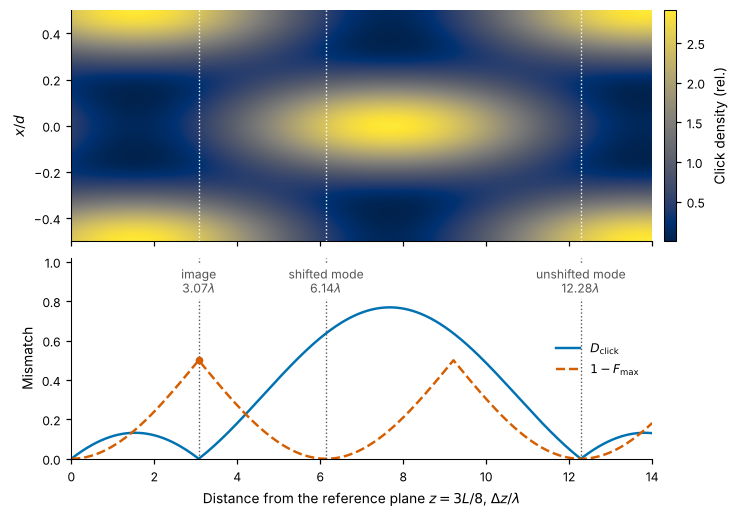

In [3]:
print("Three-order benchmark.")
d3 = 2.53
q3 = K/d3
L3 = K/(K-np.sqrt(K**2-q3**2))                       # first unshifted complex-field recurrence
z_ref = 3*L3/8                                       # reference plane of the floor-attaining pair (3L/8, 5L/8)

def intensity3(x, z):
    return np.abs(2**-.5+np.cos(q3*x)*np.exp(-2j*np.pi*z/L3))**2

def click_distance3(z2, z1=z_ref):
    # Total variation between the click densities |u|^2/d of a continuous position measurement at unit gain.
    return np.sqrt(2)/np.pi*np.abs(np.cos(2*np.pi*z2/L3)-np.cos(2*np.pi*z1/L3))

def overlap3(delta, p0=.5):
    # Shift-optimized squared overlap for populations (p1, p0, p1) with p0 + 2 p1 = 1.
    c = np.abs(np.cos(2*np.pi*delta/L3))
    return p0**2+(1-p0)**2+2*p0*(1-p0)*c

x = np.linspace(-d3/2, d3/2, 2000, endpoint=False)
dz = np.linspace(0, 14, 1401)
numeric_tv = np.array([.5*np.mean(np.abs(intensity3(x, z_ref+t)-intensity3(x, z_ref))) for t in dz])
assert np.max(np.abs(numeric_tv-click_distance3(z_ref+dz))) < 1e-6
pixel_tv = np.array([.5*np.abs((intensity3(x, z_ref+t)-intensity3(x, z_ref)).reshape(16, -1).mean(axis=1)).mean() for t in dz])
assert np.all(pixel_tv <= numeric_tv+1e-12)          # finite pixels can only reduce the distance
shifts = np.linspace(0, d3, 2001)
populations = np.array([.25, .5, .25]); beta3 = np.array([K-K/L3, K, K-K/L3])
brute = np.array([np.max(np.abs((populations*np.exp(1j*beta3*t))@np.exp(1j*np.outer([-q3, 0, q3], shifts)))**2) for t in dz])
assert np.max(np.abs(brute-overlap3(dz))) < 1e-5
grid_p0 = np.linspace(0, 1, 401); grid_delta = np.linspace(0, L3, 801)
floor = min(overlap3(grid_delta, p).min() for p in grid_p0)
assert abs(floor-.5) < 1e-9
summary['three_order'] = {'period': d3, 'first_unshifted_field_recurrence': float(L3), 'half_period_shifted_field_recurrence': float(L3/2),
                          'floor_pair': {'planes': [float(3*L3/8), float(5*L3/8)], 'separation': float(L3/4), 'overlap': float(overlap3(L3/4)),
                                         'click_distance': float(click_distance3(5*L3/8, 3*L3/8))},
                          'comparison_pair': {'planes': [float(L3/6), float(5*L3/6)], 'separation': float(2*L3/3), 'overlap': float(overlap3(2*L3/3)),
                                              'click_distance': float(click_distance3(5*L3/6, L3/6))},
                          'minimum_overlap_symmetric_states': float(floor)}
print(json.dumps(summary['three_order'], indent=2))

fig, axes = plt.subplots(2, 1, figsize=(6.6, 4.6), sharex=True, layout='constrained', height_ratios=(1.15, 1))
xm = np.linspace(-.5, .5, 241)*d3
image = axes[0].imshow(np.array([intensity3(xm, z_ref+t) for t in dz]).T, extent=(dz[0], dz[-1], -.5, .5), origin='lower',
                       aspect='auto', cmap='cividis')
fig.colorbar(image, ax=axes[0], label='Click density (rel.)', pad=.01)
axes[0].set_ylabel('$x/d$')
axes[1].plot(dz, click_distance3(z_ref+dz), color=BLUE, label=r'$D_{\mathrm{click}}$')
axes[1].plot(dz, 1-overlap3(dz), color=ORANGE, ls='--', label=r'$1-F_{\max}$')
for value, label in ((L3/4, 'image'), (L3/2, 'shifted mode'), (L3, 'unshifted mode')):
    axes[0].axvline(value, color='w', lw=.9, ls=':'); axes[1].axvline(value, color=GREY, lw=.9, ls=':')
    axes[1].annotate(f'{label}\n{value:.2f}$\\lambda$', (value, .84), ha='center', fontsize=8, color=GREY,
                     bbox=dict(fc='w', ec='none', pad=1.5))
axes[1].plot([L3/4], [.5], 'o', color=ORANGE, ms=4)
axes[1].set(xlabel=r'Distance from the reference plane $z=3L/8$, $\Delta z/\lambda$', ylabel='Mismatch', ylim=(0, 1.02), xlim=(0, 14))
axes[1].legend(loc='center right', ncols=1)
save_figure(fig, 'Three_Order_Recurrence')

## Nine modes on a square cell
The midpoint coefficients are real and even in the transverse wavevector, and so are the analyzer factors, so every pixel probability and the no-click probability agree at the two planes. With $x=\cos(2\pi s_x/d)$ and $y=\cos(2\pi s_y/d)$ the overlap amplitude is $P_0+\tfrac12P_ae^{-i\theta_a}(x+y)+P_de^{-i\theta_d}xy$. Its squared modulus is a convex quadratic in each variable, so the maximum over all shifts is reached at one of four shifts, by zero or half a period along each axis. Two cases are evaluated: a period of $1.7$ wavelengths with shell populations $(0.36,0.40,0.24)$, and a period of $73/\sqrt{2520}$ wavelengths with populations $(1/4,1/2,1/4)$ and separation $73/16$ wavelengths, for which the longitudinal wavenumbers are rational, the amplitude factorizes as $(1-ix)(1-iy)/4$ and the maximum squared overlap is exactly $1/4$.

Nine-mode two-dimensional benchmarks.
{
  "original": {
    "period": 1.7,
    "plane_separation": 1.7423712014758255,
    "beat_phases_over_pi": [
      0.6666666666666666,
      1.5509192218032117
    ],
    "longitudinal_wavenumbers_over_k": [
      1.0,
      0.8086898285,
      0.5549400666
    ],
    "click_probability": 0.6782006920415224,
    "no_click_probability": 0.32179930795847755,
    "total_variation": 1.08332125822036e-16,
    "corner_overlaps": {
      "(0,0)": 0.0512792383911164,
      "(1/2,0)": 0.15967536617345057,
      "(0,1/2)": 0.15967536617345057,
      "(1/2,1/2)": 0.6981700292619827
    },
    "max_squared_overlap": 0.6981700292619827,
    "rejection_probability": 0.3018299707380173,
    "sum_of_squared_populations": 0.184,
    "helstrom_success_worst_shift": 0.7746952724101824
  },
  "engineered": {
    "period": 1.4541948080235123,
    "plane_separation": 4.5625,
    "beat_phases_over_pi": [
      2.4999999999999996,
      7.000000000000001
    ],
    "long

Figure written: outputs/Quantum_Field_Diffraction/Nine_Mode_Benchmarks.pdf


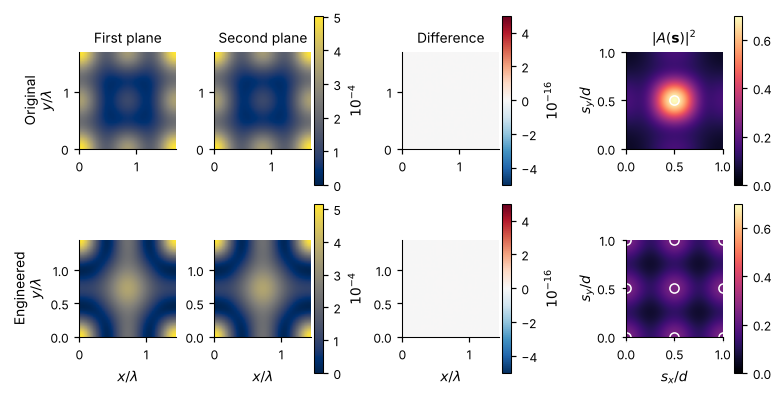

In [4]:
print("Nine-mode two-dimensional benchmarks.")
orders9 = np.array(list(product(range(-1, 2), repeat=2)))
shell9 = np.sum(orders9**2, axis=1)
efficiency = .80

class NineModes:
    # Square cell of period d (wavelengths), shell populations (central, axial, diagonal), real positive midpoint amplitudes.
    def __init__(self, d, shell_populations, separation=None, axial_beat_cycles=None):
        self.d = d; self.pop = np.array(shell_populations)[shell9]/np.array([1, 4, 4])[shell9]
        beta, _ = self.modes()
        self.beat = np.array([beta[shell9 == 0][0]-beta[shell9 == s][0] for s in (1, 2)])       # axial, diagonal
        self.separation = separation if separation is not None else 2*np.pi*axial_beat_cycles/self.beat[0]
        self.psi_in = np.sqrt(self.pop)*np.exp(-1j*beta*self.separation/2)
    def modes(self, wavelength=1.0):
        k = K/wavelength; q = K*orders9/self.d
        beta = np.sqrt(k*k-np.sum(q*q, axis=1)); directions = np.column_stack((q, beta))/k; ey = np.array([0., 1., 0.])
        transverse = ey-directions*directions[:, 1, None]
        return beta, (transverse/np.linalg.norm(transverse, axis=1, keepdims=True))@ey
    def clicks(self, psi, analyzer, n=64):
        # Pixel probabilities with the rectangular-pixel integral carried out exactly, and the no-click probability.
        x = (np.arange(n)+.5)*self.d/n; dq = orders9[:, None, :]-orders9[None, :, :]
        pixel = np.sinc(dq[:, :, 0]/n)*np.sinc(dq[:, :, 1]/n)
        e = np.exp(1j*np.outer(x, orders9[:, 0]*K/self.d)); f = np.exp(1j*np.outer(x, orders9[:, 1]*K/self.d)); a = psi*analyzer
        p = efficiency*np.einsum('im,in,jm,jn,mn->ij', e, e.conj(), f, f.conj(), a[:, None]*a.conj()[None, :]*pixel, optimize=True).real/n**2
        return p, float(1-p.sum())
    def planes(self, plane_error=0., wavelength=1.0):
        beta, analyzer = self.modes(wavelength)
        return self.clicks(self.psi_in, analyzer), self.clicks(self.psi_in*np.exp(1j*beta*(self.separation+plane_error)), analyzer)
    def click_distance(self, plane_error=0., wavelength=1.0):
        (p0, m0), (p1, m1) = self.planes(plane_error, wavelength)
        return float((np.abs(p1-p0).sum()+abs(m1-m0))/2)
    def overlap(self, sx, sy, plane_error=0., wavelength=1.0):
        # Squared overlap for lateral shifts (sx, sy) in units of the period.
        beta, _ = self.modes(wavelength); a = self.pop*np.exp(1j*beta*(self.separation+plane_error))
        return np.abs(np.exp(2j*np.pi*(np.multiply.outer(sx, orders9[:, 0])+np.multiply.outer(sy, orders9[:, 1])))@a)**2
    def corner_overlaps(self, plane_error=0., wavelength=1.0):
        # |A|^2 is a convex quadratic in each of cos(2 pi sx/d), cos(2 pi sy/d): the maximum is at one of four shifts.
        return {name: float(self.overlap(*s, plane_error, wavelength)) for name, s in
                (('(0,0)', (0., 0.)), ('(1/2,0)', (.5, 0.)), ('(0,1/2)', (0., .5)), ('(1/2,1/2)', (.5, .5)))}
    def max_overlap(self, plane_error=0., wavelength=1.0):
        return max(self.corner_overlaps(plane_error, wavelength).values())

original9 = NineModes(1.7, (.36, .40, .24), axial_beat_cycles=1/3)
engineered9 = NineModes(73/np.sqrt(2520), (.25, .50, .25), separation=73/16)
grid = np.arange(256)/256; SX, SY = np.meshgrid(grid, grid, indexing='ij')
summary['nine_mode'] = {}
for name, case in (('original', original9), ('engineered', engineered9)):
    (p_first, miss_first), (p_second, miss_second) = case.planes()
    corners = case.corner_overlaps(); sweep = case.overlap(SX, SY)
    assert abs(sweep.max()-max(corners.values())) < 1e-12 and np.isclose(case.pop.sum(), 1)       # regression check of the four-shift result
    beta, _ = case.modes()
    summary['nine_mode'][name] = {'period': float(case.d), 'plane_separation': float(case.separation),
        'beat_phases_over_pi': (case.beat*case.separation/np.pi).tolist(), 'longitudinal_wavenumbers_over_k': sorted(set(np.round(beta/K, 10)), reverse=True),
        'click_probability': float(p_first.sum()), 'no_click_probability': miss_first, 'total_variation': case.click_distance(),
        'corner_overlaps': corners, 'max_squared_overlap': max(corners.values()), 'rejection_probability': 1-max(corners.values()),
        'sum_of_squared_populations': float(np.sum(case.pop**2)),
        'helstrom_success_worst_shift': float(.5*(1+np.sqrt(1-max(corners.values()))))}
assert abs(summary['nine_mode']['engineered']['max_squared_overlap']-.25) < 1e-12
assert abs(summary['nine_mode']['engineered']['click_probability']-efficiency*(1-(1/engineered9.d)**2/2)) < 1e-12

# Matched reference projection with independent Gaussian phase errors of standard deviation sigma in the nine channels:
# acceptance = exp(-sigma^2) |A|^2 + (1 - exp(-sigma^2)) sum p^2. Monte Carlo check of the closed form.
rng = np.random.default_rng(7); sigma = .3; noise = np.exp(1j*sigma*rng.standard_normal((200000, 9)))
a_cmp = engineered9.pop*np.exp(1j*engineered9.modes()[0]*engineered9.separation)
closed = lambda A2, s: np.exp(-s*s)*A2+(1-np.exp(-s*s))*np.sum(engineered9.pop**2)
mc = (float(np.mean(np.abs(noise@engineered9.pop)**2)), float(np.mean(np.abs(noise@a_cmp)**2)))
assert abs(mc[0]-closed(1, sigma)) < 3e-3 and abs(mc[1]-closed(abs(a_cmp.sum())**2, sigma)) < 3e-3
summary['nine_mode']['engineered']['matched_projection_phase_error_0.3rad'] = {'reference_acceptance': float(closed(1, sigma)),
                                                                              'comparison_acceptance_bound': float(closed(.25, sigma))}
print(json.dumps(summary['nine_mode'], indent=2))

fig, axes = plt.subplots(2, 4, figsize=(7.0, 3.5), layout='constrained')
for row, (label, case) in enumerate((('Original', original9), ('Engineered', engineered9))):
    (p_first, _), (p_second, _) = case.planes(); top = max(p_first.max(), p_second.max())*1e4; ext = (0, case.d, 0, case.d)
    for col, prob in enumerate((p_first, p_second)):
        im = axes[row, col].imshow(prob.T*1e4, extent=ext, origin='lower', cmap='cividis', vmin=0, vmax=top)
    fig.colorbar(im, ax=axes[row, 1], pad=.03, label=r'$10^{-4}$')
    im = axes[row, 2].imshow((p_second-p_first).T*1e16, extent=ext, origin='lower', cmap='RdBu_r', vmin=-5, vmax=5)
    fig.colorbar(im, ax=axes[row, 2], pad=.03, label=r'$10^{-16}$')
    im = axes[row, 3].imshow(case.overlap(SX, SY).T, extent=(0, 1, 0, 1), origin='lower', cmap='magma', vmin=0, vmax=.7)
    fig.colorbar(im, ax=axes[row, 3], pad=.03)
    best = max(case.corner_overlaps().values())
    for sx, sy in product((0, .5, 1), repeat=2):
        if abs(float(case.overlap(sx % 1, sy % 1))-best) < 1e-9: axes[row, 3].plot(sx, sy, 'o', mfc='none', mec='w', ms=6, clip_on=False)
    axes[row, 0].set_ylabel(f'{label}\n$y/\\lambda$'); axes[row, 3].set_ylabel('$s_y/d$', labelpad=1)
for col, title in enumerate(('First plane', 'Second plane', 'Difference', r'$|A(\mathbf{s})|^2$')): axes[0, col].set_title(title)
for col in range(3): axes[1, col].set_xlabel(r'$x/\lambda$')
axes[1, 3].set_xlabel('$s_x/d$')
save_figure(fig, 'Nine_Mode_Benchmarks')

## A screen with three propagating orders
For a period between one and two wavelengths and a mirror-symmetric cell, the propagating field of each polarization is $a_0e^{i\beta_0z}+2a_1\cos(qx)e^{i\beta_1z}$. Electric intensity, flux and the click density of the imaging receiver then depend on $z$ only through $\cos[(\beta_0-\beta_1)z-\varphi]$ with $\varphi=\arg(a_1/a_0)$, so they are even about the planes $z=(\varphi+n\pi)/(\beta_0-\beta_1)$. The cell below places two planes symmetrically about such a plane for each polarization. The residual of the field profiles is the evanescent field at the nearer plane.

In [5]:
print("Three-order regime: one centred slit, period 1.265 wavelengths.")
d_t, w_t = 1.265, 0.60
beat_t = K-np.sqrt(K**2-(K/d_t)**2)               # beta_0 - beta_1
L_t = K/beat_t
x = np.linspace(-d_t/2, d_t/2, 256, endpoint=False)
separation_t = 7*L_t/4                             # |cos| of the beat phase vanishes: smallest overlap
regime = {'period': d_t, 'slit_width': w_t, 'separation': float(separation_t)}; sols_t = {}; planes_t = {}
for pol in ("TE", "TM"):
    sol = solve_periodic(d_t, [(0., w_t)], pol, extra=8, xi_scale=3); i0 = len(sol["m"])//2
    phase = np.angle(sol["S"][i0+1]/sol["S"][i0])  # relative phase of the first and zeroth orders at the screen
    centre_plane = phase/beat_t
    assert min(abs(sol["S"][i0]), abs(sol["S"][i0+1])) > 0          # Eq. for the symmetry planes needs both orders
    while centre_plane-separation_t/2 < 1.5: centre_plane += np.pi/beat_t
    za, zb = centre_plane-separation_t/2, centre_plane+separation_t/2
    (Ea, Fa), (Eb, Fb) = profiles(sol, x, za), profiles(sol, x, zb)
    xc = (np.arange(4096)+.5)*d_t/4096; ca, cb = count_density(sol, xc, za)*d_t/4096, count_density(sol, xc, zb)*d_t/4096
    p = sol["PT"][sol["PT"] > 0]/sol["T"]
    regime[pol] = {'symmetry_plane': float(centre_plane), 'planes': [float(za), float(zb)], 'E': relative(Ea, Eb), 'flux': relative(Fa, Fb), 'count_total_variation': float(.5*np.abs(cb-ca).sum()),
                   'Fmax': shift_optimized_overlap(sol, separation_t), 'Fmax_formula': float(p[1]**2+(1-p[1])**2),
                   'T': sol["T"], 'central_population': float(p[1])}
    sols_t[pol] = sol; planes_t[pol] = (za, zb)
pairs = [[profiles(sols_t[pol], x, z) for z in planes_t["TE"]] for pol in ("TE", "TM")]
regime['unpolarized_at_TE_planes'] = {'E': relative(*[.5*(pairs[0][i][0]+pairs[1][i][0]) for i in (0, 1)]),
                                      'flux': relative(*[.5*(pairs[0][i][1]+pairs[1][i][1]) for i in (0, 1)])}
# Offset between the two families of symmetry planes, reduced modulo their spacing (half the beat length).
regime['symmetry_plane_spacing'] = float(L_t/2)
regime['symmetry_plane_offset_TE_TM'] = float(((regime['TE']['symmetry_plane']-regime['TM']['symmetry_plane']+L_t/4) % (L_t/2))-L_t/4)
summary['three_order_screen'] = regime
print(json.dumps(regime, indent=2))

Three-order regime: one centred slit, period 1.265 wavelengths.
{
  "period": 1.265,
  "slit_width": 0.6,
  "separation": 4.5154786145297585,
  "TE": {
    "symmetry_plane": 3.8782645709124495,
    "planes": [
      1.6205252636475702,
      6.136003878177329
    ],
    "E": 1.5257269754781575e-06,
    "flux": 1.1567150525824377e-06,
    "count_total_variation": 2.908812784824938e-16,
    "Fmax": 0.5127066073349277,
    "Fmax_formula": 0.5127066073349265,
    "T": 0.5585142910462372,
    "central_population": 0.5797076136103899
  },
  "TM": {
    "symmetry_plane": 5.0450044507247,
    "planes": [
      2.7872651434598206,
      7.302743757989579
    ],
    "E": 2.1851987376062955e-10,
    "flux": 1.5689286740482345e-10,
    "count_total_variation": 5.908986543340725e-16,
    "Fmax": 0.513262872654879,
    "Fmax_formula": 0.513262872654878,
    "T": 0.403979283656657,
    "central_population": 0.41856636857268975
  },
  "unpolarized_at_TE_planes": {
    "E": 0.09136348026434381,
    "fl

## Exhaustive scan at a period of 2.53 wavelengths
Five orders propagate. The scan covers mirror-symmetric cells with one, two or three slits, with all widths and metal gaps at least 0.15 wavelength, and every pair of planes on a 0.05-wavelength grid in $[1.5,4]\times[8,12]$. A cell is admissible if orders $-1,0,+1$ carry at least 12% of an unpolarized photon, none of them carries less than 10% of that share, and the first image has a flux contrast of at least 0.12. For each bound on the larger of the TE and TM shift-optimized overlaps, the scan keeps the smallest unpolarized discrepancy (the larger of the electric-intensity and flux relative $L^2$ differences). Three two-slit and two three-slit frontier points are then refined locally under the same constraints.

Exhaustive scan of mirror-symmetric cells at a period of 2.53 wavelengths.
  1 slit(s): 447 cells on 2 process(es)


    291 admissible cells, 2 s; best discrepancy 0.0340


  2 slit(s): 2401 cells on 2 process(es)


    1000/2401 cells, 11 s


    2000/2401 cells, 19 s


    813 admissible cells, 22 s; best discrepancy 0.0043


... (19 outputs left out)

    cap 0.85, penalty weight 1: discrepancy 0.00053


    cap 0.85, penalty weight 100: discrepancy 0.00053


{
  "0.55": {
    "outer_centre": 0.6028617135021244,
    "outer_width": 0.1790767317067956,
    "central_width": 0.2168412626885402,
    "planes": [
      1.691061008111106,
      10.883225000411771
    ],
    "discrepancy": 0.0012009200754310029,
    "limit": 0.5500000393676525,
    "target": 0.15922346276744892,
    "participation": 0.15374348474825325,
    "contrast": 0.8530048574501421,
    "transmitted_fraction": 0.17391147830103854
  },
  "0.85": {
    "outer_centre": 0.4173438980212958,
    "outer_width": 0.20259014428952304,
    "central_width": 0.196327106674964,
    "planes": [
      2.0938796968713405,
      9.835308636975077
    ],
    "discrepancy": 0.0005323285538102791,
    "limit": 0.843438384935555,
    "target": 0.1968348738164569,
    "participation": 0.25043539607786197,
    "contrast": 0.7900519809330163,
    "transmitted_fraction": 0.20715684936671588
  }
}
{
  "0.50": {
    "half_separation_of_slits": 0.4755597737574012,
    "slit_width": 0.33185676625826815,
  

Figure written: outputs/Quantum_Field_Diffraction/Grating_Frontier.pdf


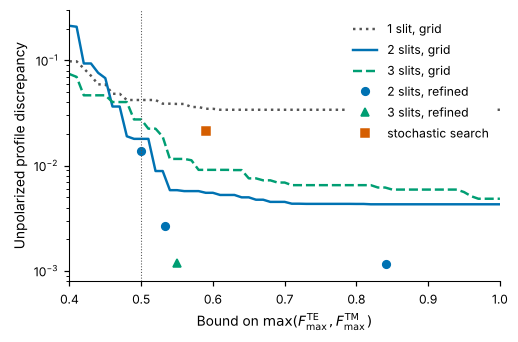

In [6]:
print("Exhaustive scan of mirror-symmetric cells at a period of 2.53 wavelengths.")
import os
from multiprocessing import get_context
d_g, gap_min = 2.53, .15
Z1 = np.round(np.arange(1.5, 4.0001, .05), 6); Z2 = np.round(np.arange(8, 12.0001, .05), 6); Z_all = np.concatenate([Z1, Z2])
caps = np.round(np.arange(.40, 1.0001, .01), 2)
x_scan = np.linspace(-d_g/2, d_g/2, 64, endpoint=False); shift_scan = np.linspace(0, d_g, 128, endpoint=False)
sep_values, sep_index = np.unique(np.round(Z2[None, :]-Z1[:, None], 6), return_inverse=True)
sep_index = sep_index.reshape(len(Z1), len(Z2))

def scan_cell(slits):
    # Every plane pair for one geometry: best discrepancy under each cap on max(F_TE, F_TM).
    E, F, overlap, PT = [], [], [], []
    for pol in ("TE", "TM"):
        sol = solve_periodic(d_g, slits, pol)
        a = sol["S"]/d_g; keep = np.abs(a*np.exp(1j*sol["kz"]*1.5)) > 1e-13*np.abs(a).max()
        a, kz, q = a[keep], sol["kz"][keep], sol["q"][keep]
        A = a[None, :]*np.exp(1j*np.outer(Z_all, kz)); P = np.exp(1j*np.outer(x_scan, q)); u = A@P.T
        F.append(np.imag(np.conj(u)*((A*(1j*kz))@P.T))/K)
        E.append(np.abs(u)**2 if pol == "TE" else np.abs((A*kz/K)@P.T)**2+np.abs((A*q/K)@P.T)**2)
        prop = sol["PT"] > 0; w = sol["PT"][prop]/sol["T"]
        amp = (w[None, :]*np.exp(1j*np.outer(sep_values, sol["kz"][prop].real)))@np.exp(1j*np.outer(sol["q"][prop], shift_scan))
        overlap.append((np.abs(amp)**2).max(axis=1)[sep_index]); PT.append(sol["PT"][prop])
    p = .5*(PT[0]+PT[1]); c = len(p)//2; target = p[c-1:c+2]
    if target.sum() < .12 or target.min()/target.sum() < .10: return None          # throughput and participation of orders -1, 0, +1
    E, F = .5*(E[0]+E[1]), .5*(F[0]+F[1]); n1 = len(Z1)
    pair = lambda Q: np.sqrt(((Q[n1:][None, :, :]-Q[:n1][:, None, :])**2).sum(-1))/np.linalg.norm(Q[:n1], axis=1)[:, None]
    worst = np.maximum(pair(E), pair(F))
    worst[F[:n1].std(axis=1)/F[:n1].mean(axis=1) < .12] = np.inf                      # contrast of the first image
    limit = np.maximum(overlap[0], overlap[1]); best = []
    for cap in caps:
        masked = np.where(limit <= cap, worst, np.inf); i = int(masked.argmin())
        best.append((float(masked.flat[i]), float(Z1[i//len(Z2)]), float(Z2[i % len(Z2)])))
    return slits, best

def cells(topology, step):
    out = []
    if topology == 1:
        out = [[(0., float(w))] for w in np.arange(gap_min, d_g-gap_min+1e-9, step/2)]
    if topology == 2:                                # centres above d/4 repeat the same screens shifted by half a period
        out = [[(-float(c), float(w)), (float(c), float(w))] for c in np.arange(.15, d_g/4+1e-9, step) for w in np.arange(gap_min, 1.3, step)
               if 2*c-w >= gap_min-1e-12 and d_g-2*c-w >= gap_min-1e-12]
    if topology == 3:
        out = [[(-float(c), float(w)), (0., float(w0)), (float(c), float(w))] for w0 in np.arange(gap_min, 2.0, step)
               for w in np.arange(gap_min, 1.1, step) for c in np.arange(.2, d_g/2, step)
               if c-w/2-w0/2 >= gap_min-1e-12 and d_g-2*c-w >= gap_min-1e-12]
    return out

def frontier(topology, step):
    todo = cells(topology, step); start = time.time(); kept = []
    workers = min(4, os.cpu_count() or 1)
    print(f"  {topology} slit(s): {len(todo)} cells on {workers} process(es)", flush=True)
    with get_context('fork').Pool(workers) as pool:
        for i, r in enumerate(pool.imap(scan_cell, todo, chunksize=8)):
            if r: kept.append(r)
            if (i+1) % 1000 == 0: print(f"    {i+1}/{len(todo)} cells, {time.time()-start:.0f} s", flush=True)
    rows = []
    for k, cap in enumerate(caps):
        slits, best = min(kept, key=lambda r: r[1][k][0])
        rows.append({'cap': float(cap), 'discrepancy': best[k][0], 'slits': slits, 'z1': best[k][1], 'z2': best[k][2]})
    print(f"    {len(kept)} admissible cells, {time.time()-start:.0f} s; best discrepancy {rows[-1]['discrepancy']:.4f}", flush=True)
    return {'cells': len(todo), 'admissible': len(kept), 'rows': rows}

scan = {1: frontier(1, .01), 2: frontier(2, .01), 3: frontier(3, .03)}

print("Local refinement of two-slit frontier points.")
def two_slit(v, extra=4, xi_scale=2.0):
    c, w, z1, z2 = v
    r = grating_metrics(d_g, [(-c, w), (c, w)], z1, z2, extra=extra, xi_scale=xi_scale)
    p = .5*(np.array(r['TE']['PT'])+np.array(r['TM']['PT'])); k = len(p)//2; flux = mixed(r, 'flux')[0]
    return r, {'discrepancy': max(discrepancy(r)), 'limit': max(r['TE']['Fmax'], r['TM']['Fmax']), 'target': float(p[k-1:k+2].sum()),
               'participation': float(p[k-1:k+2].min()/p[k-1:k+2].sum()), 'contrast': float(np.std(flux)/np.mean(flux))}

def refine(cap):
    row = min(scan[2]['rows'], key=lambda r: abs(r['cap']-cap))
    v = np.array([abs(row['slits'][0][0]), row['slits'][0][1], row['z1'], row['z2']])
    def cost(v, weight):
        c, w, z1, z2 = v
        if not (w >= gap_min and 2*c-w >= gap_min and d_g-2*c-w >= gap_min and 1.5 <= z1 <= 4 and 8 <= z2 <= 12): return 1e3
        m = two_slit(v)[1]
        if m['contrast'] < .12 or m['target'] < .12 or m['participation'] < .10: return 1e3
        return m['discrepancy']+weight*max(0, m['limit']-cap)
    for weight in (1, 100):
        for _ in range(2):
            v = minimize(cost, v, args=(weight,), method='Nelder-Mead', options={'xatol': 1e-7, 'fatol': 1e-10, 'maxiter': 3000,
                         'initial_simplex': [v]+[v+np.eye(4)[i]*s for i, s in enumerate((.01, .01, .03, .03))]}).x
        print(f"    cap {cap:.2f}, penalty weight {weight}: discrepancy {two_slit(v)[1]['discrepancy']:.5f}", flush=True)
    return v
refined = {}
for cap in (.50, .55, .85):
    v = refine(cap); metrics = two_slit(v, extra=8, xi_scale=3)[1]
    refined[f'{cap:.2f}'] = {'half_separation_of_slits': float(v[0]), 'slit_width': float(v[1]), 'planes': [float(v[2]), float(v[3])], **metrics}

print("Local refinement of three-slit frontier points under the same constraints.")
def three_slit(v, extra=4, xi_scale=2.0):
    c, w, w0, z1, z2 = v
    r = grating_metrics(d_g, [(-c, w), (0., w0), (c, w)], z1, z2, extra=extra, xi_scale=xi_scale)
    p = .5*(np.array(r['TE']['PT'])+np.array(r['TM']['PT'])); k = len(p)//2; flux = mixed(r, 'flux')[0]
    return {'discrepancy': max(discrepancy(r)), 'limit': max(r['TE']['Fmax'], r['TM']['Fmax']), 'target': float(p[k-1:k+2].sum()),
            'participation': float(p[k-1:k+2].min()/p[k-1:k+2].sum()), 'contrast': float(np.std(flux)/np.mean(flux))}
def refine3(cap):
    row = min(scan[3]['rows'], key=lambda r: abs(r['cap']-cap))
    v = np.array([row['slits'][2][0], row['slits'][2][1], row['slits'][1][1], row['z1'], row['z2']])
    def cost(v, weight):
        c, w, w0, z1, z2 = v
        if not (min(w, w0) >= gap_min and c-w/2-w0/2 >= gap_min and d_g-2*c-w >= gap_min and 1.5 <= z1 <= 4 and 8 <= z2 <= 12): return 1e3
        m = three_slit(v)
        if m['contrast'] < .12 or m['target'] < .12 or m['participation'] < .10: return 1e3
        return m['discrepancy']+weight*max(0, m['limit']-cap)
    for weight in (1, 100):
        v = minimize(cost, v, args=(weight,), method='Nelder-Mead', options={'xatol': 1e-6, 'fatol': 1e-9, 'maxiter': 1500,
                     'initial_simplex': [v]+[v+np.eye(5)[i]*s for i, s in enumerate((.01, .01, .01, .03, .03))]}).x
        print(f"    cap {cap:.2f}, penalty weight {weight}: discrepancy {three_slit(v)['discrepancy']:.5f}", flush=True)
    return v
refined3 = {}
for cap in (.55, .85):
    v = refine3(cap)
    refined3[f'{cap:.2f}'] = {'outer_centre': float(v[0]), 'outer_width': float(v[1]), 'central_width': float(v[2]), 'planes': [float(v[3]), float(v[4])],
                              **three_slit(v, extra=8, xi_scale=3),
                              'transmitted_fraction': float(.5*sum(solve_periodic(d_g, [(-v[0], v[1]), (0., v[2]), (v[0], v[1])], pol)['T'] for pol in ('TE', 'TM')))}
summary['refined_three_slit'] = refined3
print(json.dumps(refined3, indent=2))
summary['scan'] = {str(t): {'cells': scan[t]['cells'], 'admissible': scan[t]['admissible'],
                            'frontier': [[r['cap'], r['discrepancy']] for r in scan[t]['rows']]} for t in scan}
summary['refined_two_slit'] = refined
print(json.dumps(refined, indent=2))

reference_search = {'discrepancy': 0.021111, 'limit': 0.590898}      # design returned by the stochastic search notebook
fig, ax = plt.subplots(figsize=(4.6, 3.0), layout='constrained')
for topology, color, style in ((1, GREY, ':'), (2, BLUE, '-'), (3, GREEN, '--')):
    rows = [r for r in scan[topology]['rows'] if np.isfinite(r['discrepancy'])]
    ax.semilogy([r['cap'] for r in rows], [r['discrepancy'] for r in rows], color=color, ls=style, label=f"{topology} slit{'s' if topology > 1 else ''}, grid")
ax.semilogy([r['limit'] for r in refined.values()], [r['discrepancy'] for r in refined.values()], 'o', color=BLUE, ms=5, label='2 slits, refined')
ax.semilogy([r['limit'] for r in refined3.values()], [r['discrepancy'] for r in refined3.values()], '^', color=GREEN, ms=5, label='3 slits, refined')
ax.semilogy([reference_search['limit']], [reference_search['discrepancy']], 's', color=ORANGE, ms=5, label='stochastic search')
ax.axvline(.5, color=GREY, lw=.7, ls=':')
ax.set(xlabel=r'Bound on $\max(F_{\max}^{\mathrm{TE}},F_{\max}^{\mathrm{TM}})$', ylabel='Unpolarized profile discrepancy', xlim=(.4, 1), ylim=(8e-4, .3))
ax.legend(loc='upper right', frameon=True, facecolor='w', edgecolor='none', framealpha=1)
save_figure(fig, 'Grating_Frontier')

## Selected two-slit screen
The refined point with overlap bound 0.55 is analysed at the verification resolution. The cells locate the symmetry plane of each polarization, evaluate plane pairs placed symmetrically about the midpoint of the selected pair, and then report: the click distribution of an imaging receiver that collects every propagating order, the fidelity and trace distance of the transmitted polarization-mixed state for one common shift, a lower bound on the intensity discrepancy from the evanescent field, the signed change of each lateral harmonic in the two polarizations, convergence with the basis and the order cutoff, a comparison with an independent discretization, and the slit positions at which the second orders are weakest.

Two-slit screen selected from the scan: baseline at the verification resolution.


{
  "period": 2.53,
  "slits": [
    [
      -0.31838585177451173,
      0.3461895001239871
    ],
    [
      0.31838585177451173,
      0.3461895001239871
    ]
  ],
  "planes": [
    1.5000000006403411,
    10.590203905320212
  ],
  "pair_midpoint": 6.045101952980277,
  "TE": {
    "E": 0.06603021956428237,
    "flux": 0.06501865761004492,
    "Fmax": 0.5327735141144696,
    "T": 0.1593817023720977,
    "R": 0.8406182976279021,
    "PT": [
      1.2759167058433318e-05,
      0.03698597196466431,
      0.08538424010865221,
      0.03698597196466431,
      1.2759167058433323e-05
    ],
    "evanescent_amplitude_first_plane": 0.0014621081735908185
  },
  "TM": {
    "E": 0.03187433137426354,
    "flux": 0.03264321720322463,
    "Fmax": 0.4567354312341302,
    "T": 0.3547182572821729,
    "R": 0.6452817427178272,
    "PT": [
      0.006246858553257766,
      0.08936947238641346,
      0.16348559540283036,
      0.0893694723864135,
      0.006246858553257753
    ],
    "evanescent_amplit

Figure written: outputs/Quantum_Field_Diffraction/Grating_Profiles.pdf
Plane pairs placed symmetrically about the midpoint of the selected pair.


{
  "midpoint": 6.045101952980277,
  "largest_discrepancy_first_plane_beyond_1.5": 0.013159040079132081,
  "separation_range": [
    0.5,
    9.05
  ]
}


Figure written: outputs/Quantum_Field_Diffraction/Grating_Plane_Pairs.pdf
Imaging count receiver, state metrics and near-field bound for the selected screen.
{
  "imaging_receiver": {
    "click_probability_unit_gain": [
      0.2570499798271353,
      0.2570499798271353
    ],
    "absolute_total_variation_unit_gain": 0.00045382931945498904,
    "conditional_total_variation": 0.0017655294887017178,
    "conditional_total_variation_64_pixels": 0.001756769563654952,
    "conditional_total_variation_TE": 0.036896930878331624,
    "conditional_total_variation_TM": 0.01595305993793649
  },
  "transmitted_state": {
    "weight_TE": 0.31002084201539526,
    "fidelity": 0.4796829547664683,
    "trace_distance": 0.7204709184645286,
    "helstrom_success_given_transmission": 0.8602354592322643
  },
  "near_field": {
    "lower_bound_on_intensity_discrepancy": 2.5552938431561147e-06,
    "intensity_discrepancy": 0.002656824393990585,
    "relative_change_of_integrated_flux": 2.1595469981592207e-

Figure written: outputs/Quantum_Field_Diffraction/Grating_Harmonics.pdf
Convergence with the slit basis and the order cutoff, and comparison with an independent discretization.


... (8 outputs left out)

  TM, 160 cells per slit: largest amplitude difference 1.40e-03


  TM, 320 cells per slit: largest amplitude difference 6.99e-04


{
  "TE": {
    "difference_by_mesh": {
      "80": 0.006154341647680749,
      "160": 0.003075439225878874,
      "320": 0.0015372899785782049
    },
    "difference_extrapolated": 2.920697539009629e-06,
    "first_order_phase_difference_extrapolated": 2.2946351190076403e-07
  },
  "TM": {
    "difference_by_mesh": {
      "80": 0.0027934184804475713,
      "160": 0.0013979221687632356,
      "320": 0.0006993393979751974
    },
    "difference_extrapolated": 1.5006693358321867e-06,
    "first_order_phase_difference_extrapolated": 3.871070287791989e-07
  }
}
Slit-separation sweep: where the second orders are weakest.


{
  "array_factor_null_centre": 0.31625,
  "selected_centre": 0.31838585177451173,
  "TE": {
    "centre": 0.316,
    "probability": 5.368940784981272e-06
  },
  "TM": {
    "centre": 0.34600000000000003,
    "probability": 0.0018247252045171594
  }
}


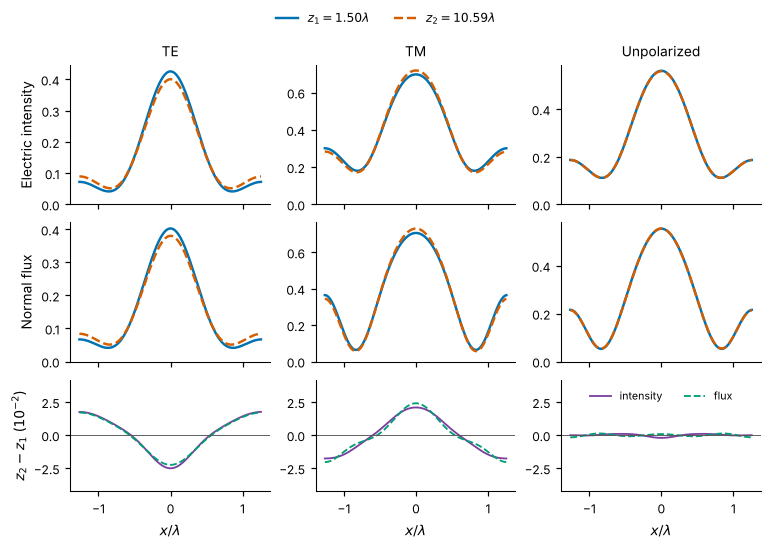

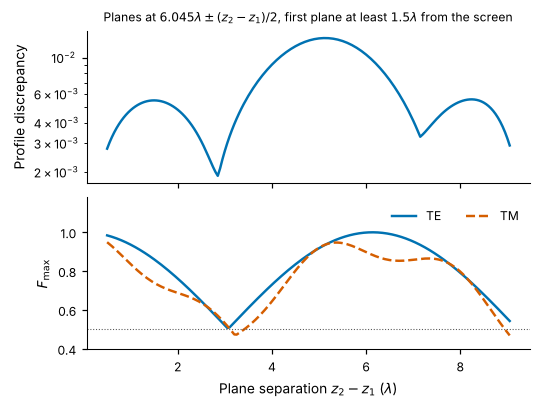

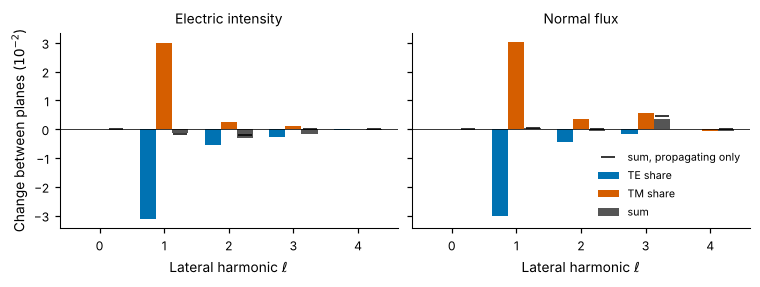

In [7]:
print("Two-slit screen selected from the scan: baseline at the verification resolution.")
design = refined['0.55']
c_g, w_g = design['half_separation_of_slits'], design['slit_width']
z1_g, z2_g = design['planes']
slits_g = [(-c_g, w_g), (c_g, w_g)]
base = grating_metrics(d_g, slits_g, z1_g, z2_g, extra=8, xi_scale=3)
coarse = grating_metrics(d_g, slits_g, z1_g, z2_g, extra=4, xi_scale=2)
unpolarized = discrepancy(base)
order_p = .5*(np.array(base['TE']['PT'])+np.array(base['TM']['PT']))
beat_g = K-np.sqrt(K**2-(K/d_g)**2); L_g = K/beat_g
symmetry = {}
for pol in ("TE", "TM"):
    sol = solve_periodic(d_g, slits_g, pol, extra=8, xi_scale=3); i0 = len(sol["m"])//2
    symmetry[pol] = float((np.angle(sol["S"][i0+1]/sol["S"][i0])/beat_g+L_g/4) % (L_g/2)+L_g/4)   # plane nearest the pair midpoint
    base[pol]['evanescent_amplitude_first_plane'] = float(np.linalg.norm(
        (sol["S"]*np.exp(1j*sol["kz"]*z1_g))[sol["PT"] == 0])/np.linalg.norm((sol["S"]*np.exp(1j*sol["kz"]*z1_g))))
summary['grating'] = {'period': d_g, 'slits': slits_g, 'planes': [z1_g, z2_g], 'pair_midpoint': (z1_g+z2_g)/2,
                      'TE': {k: base['TE'][k] for k in ('E', 'flux', 'Fmax', 'T', 'R', 'PT', 'evanescent_amplitude_first_plane')},
                      'TM': {k: base['TM'][k] for k in ('E', 'flux', 'Fmax', 'T', 'R', 'PT', 'evanescent_amplitude_first_plane')},
                      'unpolarized': {'E': unpolarized[0], 'flux': unpolarized[1], 'T': float(order_p.sum())},
                      'order_probabilities_unpolarized': order_p.tolist(), 'target_order_throughput': float(order_p[1:4].sum()),
                      'symmetry_plane': symmetry, 'slit_separation_over_period': 2*c_g/d_g,
                      'resolution_change': max(abs(a-b) for a, b in zip(discrepancy(base), discrepancy(coarse)))}
assert all(abs(base[p]['T']+base[p]['R']-1) < 1e-10 for p in ('TE', 'TM'))
print(json.dumps(summary['grating'], indent=2))

fig, axes = plt.subplots(3, 3, figsize=(6.9, 4.9), sharex=True, layout='constrained', height_ratios=(1, 1, .8))
columns = (('TE', lambda key: base[key]['TE']), ('TM', lambda key: base[key]['TM']), ('Unpolarized', lambda key: mixed(base, key)))
for j, (title, getter) in enumerate(columns):
    for i, (key, label) in enumerate((('E', 'Electric intensity'), ('flux', 'Normal flux'))):
        first, second = getter(key)
        axes[i, j].plot(base['x'], first, color=BLUE, label=f'$z_1={z1_g:.2f}\\lambda$')
        axes[i, j].plot(base['x'], second, color=ORANGE, ls='--', label=f'$z_2={z2_g:.2f}\\lambda$')
        axes[i, j].set_ylim(0, None)
        axes[2, j].plot(base['x'], (second-first)*100, color=(PURPLE, GREEN)[i], ls=('-', '--')[i], lw=1.2, label=('intensity', 'flux')[i])
        if j == 0: axes[i, j].set_ylabel(label)
    axes[2, j].axhline(0, color=GREY, lw=.6); axes[2, j].set_ylim(-4.2, 4.2)
    axes[0, j].set_title(title); axes[2, j].set_xlabel(r'$x/\lambda$')
axes[2, 0].set_ylabel(r'$z_2-z_1$ ($10^{-2}$)'); axes[2, 2].legend(loc='upper center', ncols=2, fontsize=7)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='outside upper center', ncols=2, handlelength=1.8)
save_figure(fig, 'Grating_Profiles')

print("Plane pairs placed symmetrically about the midpoint of the selected pair.")
sols_g = [solve_periodic(d_g, slits_g, pol, extra=4, xi_scale=2.0) for pol in ("TE", "TM")]
def pair_discrepancy(za, zb):
    pairs = [[profiles(sol, base['x'], z) for z in (za, zb)] for sol in sols_g]
    return max(relative(*[.5*(pairs[0][i][k]+pairs[1][i][k]) for i in (0, 1)]) for k in (0, 1))
midpoint_g = (z1_g+z2_g)/2
half = np.linspace(.25, 5.25, 201)
pair_curve = np.array([pair_discrepancy(midpoint_g-t, midpoint_g+t) for t in half])
pair_overlap = np.array([[shift_optimized_overlap(sol, 2*t, n=1024) for sol in sols_g] for t in half])
inside = half <= midpoint_g-1.5
summary['symmetric_pairs'] = {'midpoint': midpoint_g, 'largest_discrepancy_first_plane_beyond_1.5': float(pair_curve[inside].max()),
                              'separation_range': [float(2*half[inside].min()), float(2*half[inside].max())]}
print(json.dumps(summary['symmetric_pairs'], indent=2))
fig, axes = plt.subplots(2, 1, figsize=(4.8, 3.6), sharex=True, layout='constrained')
axes[0].semilogy(2*half[inside], pair_curve[inside], color=BLUE); axes[0].set_ylabel('Profile discrepancy')
axes[1].plot(2*half[inside], pair_overlap[inside, 0], color=BLUE, label='TE'); axes[1].plot(2*half[inside], pair_overlap[inside, 1], color=ORANGE, ls='--', label='TM')
axes[0].set_title(f'Planes at ${midpoint_g:.3f}\\lambda\\pm(z_2-z_1)/2$, first plane at least $1.5\\lambda$ from the screen', fontsize=8)
axes[1].axhline(.5, color=GREY, lw=.7, ls=':'); axes[1].set(xlabel=r'Plane separation $z_2-z_1$ ($\lambda$)', ylabel=r'$F_{\max}$', ylim=(.4, 1.18))
axes[1].legend(loc='upper right', ncols=2)
save_figure(fig, 'Grating_Plane_Pairs')

print("Imaging count receiver, state metrics and near-field bound for the selected screen.")
sols_v = {pol: solve_periodic(d_g, slits_g, pol, extra=8, xi_scale=3) for pol in ("TE", "TM")}
xc = (np.arange(4096)+.5)*d_g/4096
counts = {pol: [count_density(sols_v[pol], xc, z)*d_g/4096 for z in (z1_g, z2_g)] for pol in sols_v}
unpol_counts = [.5*(counts["TE"][i]+counts["TM"][i]) for i in (0, 1)]
tv = lambda a, b: float(.5*np.abs(b-a).sum())
binned = lambda p, n: p.reshape(n, -1).sum(axis=1)
receiver = {'click_probability_unit_gain': [float(p.sum()) for p in unpol_counts],
            'absolute_total_variation_unit_gain': tv(*unpol_counts), 'conditional_total_variation': tv(*unpol_counts)/float(unpol_counts[0].sum()),
            'conditional_total_variation_64_pixels': tv(*[binned(p, 64) for p in unpol_counts])/float(unpol_counts[0].sum()),
            'conditional_total_variation_TE': tv(*counts["TE"])/float(counts["TE"][0].sum()),
            'conditional_total_variation_TM': tv(*counts["TM"])/float(counts["TM"][0].sum())}
state = common_shift_state_metrics(sols_v["TE"], sols_v["TM"], z2_g-z1_g)
state['helstrom_success_given_transmission'] = .5*(1+state['trace_distance'])
xh = np.linspace(-d_g/2, d_g/2, 2048, endpoint=False)
full = [[profiles(sols_v[pol], xh, z) for z in (z1_g, z2_g)] for pol in ("TE", "TM")]
E_un = [.5*(full[0][i][0]+full[1][i][0]) for i in (0, 1)]; S_un = [.5*(full[0][i][1]+full[1][i][1]) for i in (0, 1)]
near_field = {'lower_bound_on_intensity_discrepancy': float(abs(E_un[1].mean()-E_un[0].mean())/np.sqrt(np.mean(E_un[0]**2))),
              'intensity_discrepancy': relative(*E_un), 'relative_change_of_integrated_flux': float(abs(S_un[1].mean()-S_un[0].mean())/S_un[0].mean())}
summary['grating'].update({'imaging_receiver': receiver, 'transmitted_state': state, 'near_field': near_field})
print(json.dumps({'imaging_receiver': receiver, 'transmitted_state': state, 'near_field': near_field}, indent=2))

print("Harmonic audit: signed change of each lateral harmonic between the two planes.")
def harmonics(profile, x, count=5):
    q = K/d_g; return np.array([(1 if l == 0 else 2)*np.mean(profile*np.cos(l*q*x)) for l in range(count)])
audit = {}
for k, key in enumerate(('E', 'flux')):
    scale = np.sqrt(np.mean(((E_un, S_un)[k][0])**2))
    parts = {pol: .5*(harmonics(full[j][1][k], xh)-harmonics(full[j][0][k], xh))/scale for j, pol in enumerate(("TE", "TM"))}
    prop = [[profiles(sols_v[pol], xh, z, propagating_only=True)[k] for z in (z1_g, z2_g)] for pol in ("TE", "TM")]
    prop_sum = sum(.5*(harmonics(p[1], xh)-harmonics(p[0], xh)) for p in prop)/scale
    audit[key] = {'TE': parts["TE"].tolist(), 'TM': parts["TM"].tolist(), 'sum': (parts["TE"]+parts["TM"]).tolist(), 'sum_propagating_only': prop_sum.tolist()}
summary['grating']['harmonic_audit'] = audit
print(json.dumps(audit, indent=2))
fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.5), layout='constrained', sharey=True)
for ax, key, title in zip(axes, ('E', 'flux'), ('Electric intensity', 'Normal flux')):
    l = np.arange(5)
    ax.bar(l-.25, 100*np.array(audit[key]['TE']), .25, color=BLUE, label='TE share'); ax.bar(l, 100*np.array(audit[key]['TM']), .25, color=ORANGE, label='TM share')
    ax.bar(l+.25, 100*np.array(audit[key]['sum']), .25, color=GREY, label='sum')
    ax.plot(l+.25, 100*np.array(audit[key]['sum_propagating_only']), 'k_', ms=9, label='sum, propagating only')
    ax.axhline(0, color='k', lw=.5); ax.set(title=title, xlabel=r'Lateral harmonic $\ell$')
axes[0].set_ylabel(r'Change between planes ($10^{-2}$)'); axes[1].legend(loc='lower right', fontsize=7)
save_figure(fig, 'Grating_Harmonics')

print("Convergence with the slit basis and the order cutoff, and comparison with an independent discretization.")
convergence = []
for extra in (0, 4, 8, 12):
    for xi_scale in (1., 2., 3., 4.):
        r = grating_metrics(d_g, slits_g, z1_g, z2_g, extra=extra, xi_scale=xi_scale); phases = []; balance = []
        for pol in ("TE", "TM"):
            sol = solve_periodic(d_g, slits_g, pol, extra=extra, xi_scale=xi_scale); i0 = len(sol["m"])//2
            phases.append(float(np.angle(sol["S"][i0+1]/sol["S"][i0]))); balance.append(abs(sol["T"]+sol["R"]-1)); orders = len(sol["m"])
        convergence.append({'basis_functions_per_slit': int(K*w_g/2)+8+extra, 'retained_orders': orders, 'discrepancy': max(discrepancy(r)),
                            'phase_TE': phases[0], 'phase_TM': phases[1], 'energy_balance_error': max(balance)})
    print(f"  basis {convergence[-1]['basis_functions_per_slit']}: discrepancies {[round(c['discrepancy'], 8) for c in convergence[-4:]]}", flush=True)
independent = {}
for pol in ("TE", "TM"):
    ref = sols_v[pol]["S"][sols_v[pol]["PT"] > 0]; mesh = {}
    for cells in (80, 160, 320):
        mesh[cells] = solve_subdomain(d_g, slits_g, pol, cells)
        print(f"  {pol}, {cells} cells per slit: largest amplitude difference {np.abs(mesh[cells]-ref).max()/abs(ref[2]):.2e}", flush=True)
    extrapolated = 2*mesh[320]-mesh[160]                  # the differences halve with the mesh size
    independent[pol] = {'difference_by_mesh': {str(c): float(np.abs(mesh[c]-ref).max()/abs(ref[2])) for c in mesh},
                        'difference_extrapolated': float(np.abs(extrapolated-ref).max()/abs(ref[2])),
                        'first_order_phase_difference_extrapolated': float(abs(np.angle(extrapolated[3]/extrapolated[2])-np.angle(ref[3]/ref[2])))}
summary['grating']['convergence'] = convergence; summary['grating']['independent_discretization'] = independent
print(json.dumps(independent, indent=2))

print("Slit-separation sweep: where the second orders are weakest.")
centres = np.linspace(.26, .38, 121); second = {pol: [] for pol in ("TE", "TM")}
for c in centres:
    for pol in second:
        sol = solve_periodic(d_g, [(-c, w_g), (c, w_g)], pol); second[pol].append(sol["PT"][sol["PT"] > 0][0])
summary['grating']['second_order_minimum'] = {'array_factor_null_centre': d_g/8, 'selected_centre': c_g,
    **{pol: {'centre': float(centres[int(np.argmin(v))]), 'probability': float(np.min(v))} for pol, v in second.items()}}
print(json.dumps(summary['grating']['second_order_minimum'], indent=2))

## Sensitivity of the ideal modes
The entrance coefficients, the period and the plane positions are held fixed. Either the second plane is displaced or the wavelength is changed.

Sensitivity of the ideal modal benchmarks.
  nine modes, original: plane and wavelength sweeps


  nine modes, engineered: plane and wavelength sweeps


{
  "three": {
    "plane_half_width_for_0.01": 0.060476740716142875,
    "detuning_half_width_for_0.01": 0.004572296624656309,
    "overlap_range_plane": [
      0.5,
      0.5510743522994292
    ],
    "overlap_range_detuning": [
      0.5,
      0.517144409156093
    ],
    "slope_per_wavelength_of_plane_error": 0.16285877563342496
  },
  "original": {
    "plane_half_width_for_0.01": 0.019374581330236142,
    "detuning_half_width_for_0.01": 0.0064533390071882775,
    "overlap_range_plane": [
      0.5094828090110171,
      0.8520955123171257
    ],
    "overlap_range_detuning": [
      0.6464294593796351,
      0.7485871049957147
    ]
  },
  "engineered": {
    "plane_half_width_for_0.01": 0.016853424594622968,
    "detuning_half_width_for_0.01": 0.0008246908652097424,
    "overlap_range_plane": [
      0.2500000000000001,
      0.5333005066755064
    ],
    "overlap_range_detuning": [
      0.2500000000000001,
      0.725173274098621
    ]
  }
}


Figure written: outputs/Quantum_Field_Diffraction/Ideal_Mode_Sensitivity.pdf


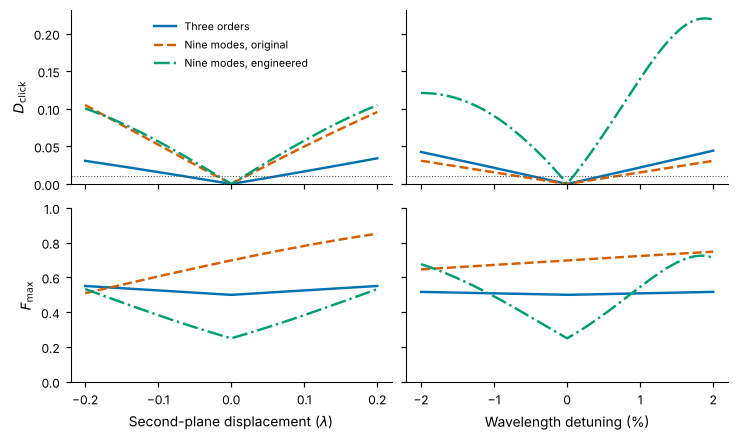

In [8]:
print("Sensitivity of the ideal modal benchmarks.")
plane_error = np.linspace(-.2, .2, 161)
detuning = np.linspace(-.02, .02, 161)

def click_distance3_detuned(eps):
    # Fixed period, fixed planes (3L/8, 5L/8) and fixed entrance coefficients; only the wavelength changes.
    k = K/(1+eps); L = K/(k-np.sqrt(k*k-q3**2))
    return np.sqrt(2)/np.pi*abs(np.cos(2*np.pi*(5*L3/8)/L)-np.cos(2*np.pi*(3*L3/8)/L))
def overlap3_detuned(eps):
    k = K/(1+eps); L = K/(k-np.sqrt(k*k-q3**2)); return float(overlap3(L3/4*L3/L))

def half_width(axis, values, level):
    # Smallest |perturbation| at which the curve reaches the level, by linear interpolation; None if never reached.
    axis, values = np.asarray(axis, float), np.asarray(values, float); crossings = []
    for i in range(len(axis)-1):
        a, b = values[i]-level, values[i+1]-level
        if a == 0: crossings.append(abs(axis[i]))
        elif a*b < 0: crossings.append(abs(axis[i]+(axis[i+1]-axis[i])*a/(a-b)))
    return float(min(crossings)) if crossings else None

ideal = {'three': {'D_plane': click_distance3(5*L3/8+plane_error, 3*L3/8), 'D_detuning': np.array([click_distance3_detuned(e) for e in detuning]),
                   'F_plane': overlap3(L3/4+plane_error), 'F_detuning': np.array([overlap3_detuned(e) for e in detuning])}}
for name, case in (('original', original9), ('engineered', engineered9)):
    print(f"  nine modes, {name}: plane and wavelength sweeps", flush=True)
    ideal[name] = {'D_plane': np.array([case.click_distance(plane_error=t) for t in plane_error]),
                   'D_detuning': np.array([case.click_distance(wavelength=1+e) for e in detuning]),
                   'F_plane': np.array([case.max_overlap(plane_error=t) for t in plane_error]),
                   'F_detuning': np.array([case.max_overlap(wavelength=1+e) for e in detuning])}
summary['ideal_sensitivity'] = {name: {'plane_half_width_for_0.01': half_width(plane_error, v['D_plane'], .01),
                                       'detuning_half_width_for_0.01': half_width(detuning, v['D_detuning'], .01),
                                       'overlap_range_plane': [float(v['F_plane'].min()), float(v['F_plane'].max())],
                                       'overlap_range_detuning': [float(v['F_detuning'].min()), float(v['F_detuning'].max())]} for name, v in ideal.items()}
summary['ideal_sensitivity']['three']['slope_per_wavelength_of_plane_error'] = float(np.sqrt(2)/np.pi*np.sqrt(2)/2*K/L3)
print(json.dumps(summary['ideal_sensitivity'], indent=2))

fig, axes = plt.subplots(2, 2, figsize=(6.6, 3.9), layout='constrained', sharex='col', sharey='row')
styles = (('three', BLUE, '-', 'Three orders'), ('original', ORANGE, '--', 'Nine modes, original'), ('engineered', GREEN, '-.', 'Nine modes, engineered'))
for col, (axis, key, label, scale) in enumerate(((plane_error, 'plane', r'Second-plane displacement ($\lambda$)', 1), (detuning, 'detuning', 'Wavelength detuning (%)', 100))):
    for name, color, style, text in styles:
        axes[0, col].plot(axis*scale, ideal[name][f'D_{key}'], color=color, ls=style, label=text)
        axes[1, col].plot(axis*scale, ideal[name][f'F_{key}'], color=color, ls=style)
    axes[0, col].axhline(.01, color=GREY, lw=.7, ls=':'); axes[1, col].set_xlabel(label)
axes[0, 0].set_ylabel(r'$D_{\mathrm{click}}$'); axes[1, 0].set_ylabel(r'$F_{\max}$'); axes[0, 0].set_ylim(0, None); axes[1, 0].set_ylim(0, 1)
axes[0, 0].legend(loc='upper center', fontsize=7)
save_figure(fig, 'Ideal_Mode_Sensitivity')

## Sensitivity of the selected screen
One quantity is perturbed at a time: wavelength, either plane, both slit widths, the slit separation, one slit edge, and the TE power fraction of the input. For wavelength and geometry errors the sweep is repeated with the two planes re-placed inside the plane ranges of the scan. A final step draws all errors together at random.

Sensitivity of the selected two-slit screen (fixed geometry and planes, one perturbation at a time).


  wavelength: 161 solves in 8.6 s, worst discrepancy 0.163


  z1: 81 solves in 4.3 s, worst discrepancy 0.081


  z2: 81 solves in 4.4 s, worst discrepancy 0.083


  width: 61 solves in 3.3 s, worst discrepancy 0.075


  centre: 61 solves in 3.3 s, worst discrepancy 0.500


... (27 outputs left out)

    750/1000 samples


    1000/1000 samples


[
  {
    "geometry_half_range": 0.002,
    "plane_half_range": 0.02,
    "wavelength_half_range": 0.001,
    "samples": 1000,
    "median": 0.010283913690638587,
    "percentile_95": 0.020983576100253764,
    "largest": 0.03311129858310137
  },
  {
    "geometry_half_range": 0.005,
    "plane_half_range": 0.05,
    "wavelength_half_range": 0.002,
    "samples": 1000,
    "median": 0.023434477719607966,
    "percentile_95": 0.049353253709737796,
    "largest": 0.07933026016249864
  }
]
{
  "wavelength": {
    "half_width_for_0.05": 0.005727944996451807,
    "throughput_range": [
      0.25627497583984776,
      0.25779946968986733
    ],
    "Fmax_range": [
      0.4378409466638714,
      0.5826483286431721
    ],
    "half_width_for_0.05_planes_replaced": 0.017316332841690017
  },
  "z1": {
    "half_width_for_0.05": 0.12197732679855829,
    "throughput_range": [
      0.2570500457201394,
      0.2570500457201394
    ],
    "Fmax_range": [
      0.4367761967420076,
      0.58337867854

Figure written: outputs/Quantum_Field_Diffraction/Grating_Sensitivity.pdf


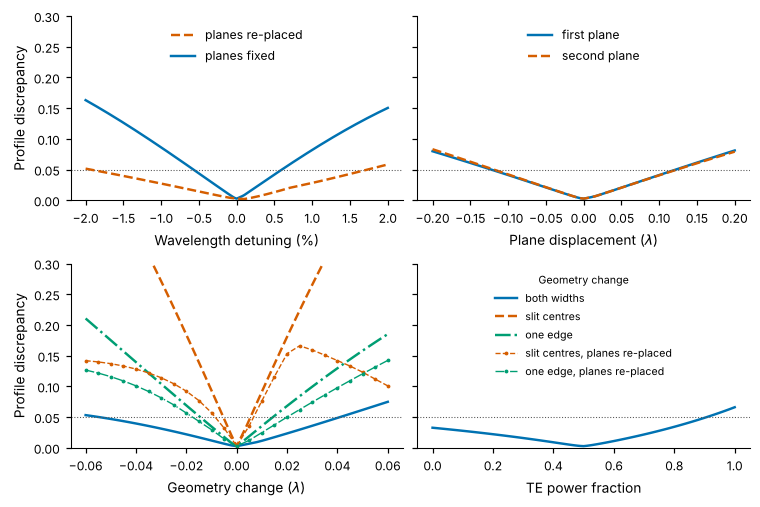

In [9]:
print("Sensitivity of the selected two-slit screen (fixed geometry and planes, one perturbation at a time).")
(c_left, _), (c_right, _) = slits_g
def worst(result, te_fraction=.5):
    return max(discrepancy(result, te_fraction))
def perturbed(scale=1., dz1=0., dz2=0., dwidth=0., dcentre=0., dedge=0.):
    # scale = nominal wavelength / operating wavelength. dedge moves the outer edge of one slit only.
    slits = [(c_left-dcentre, w_g+dwidth), (c_right+dcentre+dedge/2, w_g+dwidth+dedge)]
    return grating_metrics(d_g*scale, [(c*scale, w*scale) for c, w in slits], (z1_g+dz1)*scale, (z2_g+dz2)*scale)

sweeps = {'wavelength': np.linspace(-.02, .02, 161), 'z1': np.linspace(-.2, .2, 81), 'z2': np.linspace(-.2, .2, 81),
          'width': np.linspace(-.06, .06, 61), 'centre': np.linspace(-.06, .06, 61), 'edge': np.linspace(-.06, .06, 61),
          'te_fraction': np.linspace(0, 1, 101)}
builders = {'wavelength': lambda v: perturbed(scale=1/(1+v)), 'z1': lambda v: perturbed(dz1=v), 'z2': lambda v: perturbed(dz2=v),
            'width': lambda v: perturbed(dwidth=v), 'centre': lambda v: perturbed(dcentre=v), 'edge': lambda v: perturbed(dedge=v)}
robust = {}
for name, build in builders.items():
    start = time.time(); rows = []
    for value in sweeps[name]:
        r = build(value); e, f = discrepancy(r)
        rows.append((e, f, .5*(r['TE']['T']+r['TM']['T']), r['TE']['Fmax'], r['TM']['Fmax']))
    robust[name] = np.array(rows)
    print(f"  {name}: {len(rows)} solves in {time.time()-start:.1f} s, worst discrepancy {robust[name][:, :2].max():.3f}", flush=True)
nominal = perturbed()
robust['te_fraction'] = np.array([discrepancy(nominal, t) for t in sweeps['te_fraction']])


print("  wavelength sweep with the two planes re-placed at each wavelength", flush=True)
def refit_planes(scale=1., slits=None, span=.6):
    # Solve once, then move the two planes within +-span of their nominal positions while keeping them
    # inside the plane ranges of the scan (first plane at least 1.5 nominal wavelengths from the screen).
    slits = slits_g if slits is None else slits
    x = np.linspace(-d_g*scale/2, d_g*scale/2, 256, endpoint=False)
    sols = [solve_periodic(d_g*scale, [(c*scale, w*scale) for c, w in slits], pol, extra=4, xi_scale=2.0) for pol in ("TE", "TM")]
    def cost(shift):
        z = np.array([z1_g, z2_g])+shift
        if not (1.5-1e-9 <= z[0] <= 4 and 8 <= z[1] <= 12 and np.all(np.abs(shift) <= span)): return 1e3
        pairs = [[profiles(sol, x, zz*scale) for zz in z] for sol in sols]
        return max(relative(*[.5*(pairs[0][i][k]+pairs[1][i][k]) for i in (0, 1)]) for k in (0, 1))
    grid = [(cost(np.array([a, b])), a, b) for a in np.linspace(0, span, 25) for b in np.linspace(-span, span, 49)]
    _, a, b = min(grid)
    fit = minimize(cost, [a, b], method='Nelder-Mead', options={'xatol': 1e-7, 'fatol': 1e-10, 'initial_simplex': [[a, b], [a+.01, b], [a, b+.01]]})
    return float(fit.fun), fit.x.tolist()
refit_axis = np.linspace(-.02, .02, 41); refit = []
for i, value in enumerate(refit_axis):
    refit.append(refit_planes(1/(1+value)))
    if i % 5 == 0: print(f"    detuning {value:+.3%}: discrepancy {refit[-1][0]:.4f}", flush=True)
refit_values = np.array([r[0] for r in refit])
print("  geometry sweeps with the two planes re-placed", flush=True)
geometry_axis = np.linspace(-.06, .06, 25); geometry_refit = {}
for name in ('centre', 'edge'):
    rows = []
    for i, value in enumerate(geometry_axis):
        slits = [(c_left-value, w_g), (c_right+value, w_g)] if name == 'centre' else [(c_left, w_g), (c_right+value/2, w_g+value)]
        rows.append(refit_planes(slits=slits)[0])
        if i % 8 == 0: print(f"    {name} {value:+.3f}: discrepancy {rows[-1]:.4f}", flush=True)
    geometry_refit[name] = np.array(rows)

level = .05
tolerance = {}
for name in builders:
    worst_curve = robust[name][:, :2].max(axis=1)
    tolerance[name] = {'half_width_for_0.05': half_width(sweeps[name], worst_curve, level),
                       'throughput_range': [float(robust[name][:, 2].min()), float(robust[name][:, 2].max())],
                       'Fmax_range': [float(robust[name][:, 3:].min()), float(robust[name][:, 3:].max())]}
ok = sweeps['te_fraction'][robust['te_fraction'].max(axis=1) <= level]
tolerance['te_fraction'] = {'interval_for_0.05': [float(ok.min()), float(ok.max())],
                            'best_fraction': float(sweeps['te_fraction'][robust['te_fraction'].max(axis=1).argmin()]),
                            'best_value': float(robust['te_fraction'].max(axis=1).min())}
tolerance['wavelength_with_plane_refit'] = {'worst_over_2_percent': float(refit_values.max()), 'at_plus_minus_1_percent': [float(refit_values[10]), float(refit_values[30])], 'best': float(refit_values.min()),
                                            'plane_moves_at_plus_1_percent': refit[30][1], 'plane_moves_at_minus_1_percent': refit[10][1]}
for name in ('centre', 'edge'):
    tolerance[name]['half_width_for_0.05_planes_replaced'] = half_width(geometry_axis, geometry_refit[name], level)
    tolerance[name]['worst_planes_replaced'] = float(geometry_refit[name].max())
tolerance['wavelength']['half_width_for_0.05_planes_replaced'] = half_width(refit_axis, refit_values, level)

print("  joint random errors (all quantities perturbed together, independent and uniform)", flush=True)
def joint(geometry, plane, wavelength, samples=1000, seed=11):
    rng = np.random.default_rng(seed); values = []
    for i in range(samples):
        u = rng.uniform(-1, 1, 7); scale = 1/(1+wavelength*u[6])
        slits = [(c_left+geometry*u[0], w_g+geometry*u[1]), (c_right+geometry*u[2], w_g+geometry*u[3])]
        r = grating_metrics(d_g*scale, [(c*scale, w*scale) for c, w in slits], (z1_g+plane*u[4])*scale, (z2_g+plane*u[5])*scale)
        values.append(max(discrepancy(r)))
        if (i+1) % 250 == 0: print(f"    {i+1}/{samples} samples", flush=True)
    values = np.array(values)
    return {'geometry_half_range': geometry, 'plane_half_range': plane, 'wavelength_half_range': wavelength, 'samples': samples,
            'median': float(np.median(values)), 'percentile_95': float(np.percentile(values, 95)), 'largest': float(values.max())}
tolerance['joint'] = [joint(.002, .02, .001), joint(.005, .05, .002)]
print(json.dumps(tolerance['joint'], indent=2))
summary['grating_sensitivity'] = tolerance
print(json.dumps(tolerance, indent=2))

fig, axes = plt.subplots(2, 2, figsize=(6.8, 4.5), layout='constrained', sharey=True)
panels = ((axes[0, 0], (('wavelength', 100, BLUE, '-', None),), 'Wavelength detuning (%)'),
          (axes[0, 1], (('z1', 1, BLUE, '-', 'first plane'), ('z2', 1, ORANGE, '--', 'second plane')), r'Plane displacement ($\lambda$)'),
          (axes[1, 0], (('width', 1, BLUE, '-', 'both widths'), ('centre', 1, ORANGE, '--', 'slit centres'), ('edge', 1, GREEN, '-.', 'one edge')), r'Geometry change ($\lambda$)'),
          (axes[1, 1], (('te_fraction', 1, BLUE, '-', None),), 'TE power fraction'))
for ax, curves, label in panels:
    for name, scale, color, style, text in curves:
        ax.plot(sweeps[name]*scale, robust[name][:, :2].max(axis=1), color=color, ls=style, label=text)
    ax.axhline(level, color=GREY, lw=.7, ls=':'); ax.set_xlabel(label)
    if curves[0][4]: ax.legend(loc='upper center')
axes[0, 0].plot(refit_axis*100, refit_values, color=ORANGE, ls='--', label='planes re-placed')
axes[0, 0].plot([], [], color=BLUE, label='planes fixed'); axes[0, 0].legend(loc='upper center')
axes[1, 0].plot(geometry_axis, geometry_refit['centre'], color=ORANGE, lw=.9, ls='--', marker='.', ms=3, label='slit centres, planes re-placed')
axes[1, 0].plot(geometry_axis, geometry_refit['edge'], color=GREEN, lw=.9, ls='-.', marker='.', ms=3, label='one edge, planes re-placed')
axes[1, 0].get_legend().remove()
axes[1, 1].legend(*axes[1, 0].get_legend_handles_labels(), loc='upper center', fontsize=7, title='Geometry change', title_fontsize=7)
for ax in axes[:, 0]: ax.set_ylabel('Profile discrepancy')
axes[0, 0].set_ylim(0, .3)
save_figure(fig, 'Grating_Sensitivity')

In [10]:
print("Saving the numerical summary.")
summary_path = work_dir/'self_imaging_recurrence_summary.json'
summary_path.write_text(json.dumps(summary, indent=2))
print(summary_path)
if backup_dir is not None:
    import shutil
    for item in [summary_path, *sorted(work_dir.glob('*.pdf')), *sorted(work_dir.glob('*.png'))]:
        shutil.copy2(item, backup_dir/item.name)
    print('Summary and figures copied to', backup_dir)

Saving the numerical summary.
outputs/Quantum_Field_Diffraction/self_imaging_recurrence_summary.json
